---
### __An Introduction to Machine Learning__

You have data: customer records, sales history, sensor readings, but you do not have a formula. You cannot write down the exact rule that predicts which customers will churn, which transactions are fraudulent, or when equipment will fail. That is where machine learning steps in. Instead of hand-coding the logic, you feed data to an algorithm and let it discover the patterns. The payoff is enormous: predictions that scale across millions of records, decisions grounded in evidence rather than intuition, and systems that improve as they see more data.

But machine learning does not exist in isolation. It sits at the intersection of computer science, mathematics, and statistics, with each discipline bringing essential tools and ways of thinking. In this lesson, you will build a mental model of that landscape, understand the core vocabulary and concepts that show up across all machine learning work, learn how the type of data you have shapes the models you build, and discover the workflows that separate models that work from models that merely look good on paper.

---
### __An introduction to predictive modelling__

Imagine you work at a bank and someone asks: "Will this loan applicant repay?" You have historical records, including ages, incomes, and repayment histories, but no crystal ball. __Predictive modeling__ is how data scientists answer that question systematically. 



### __How to train and assess ML models__

Imagine you build a model that predicts house prices. It fits your data beautifully, but when you run it on new properties, the predictions are way off. What went wrong? The answer almost always comes down to how the model was trained and whether you tested it fairly. Here, you will see the three core steps every machine learning workflow depends on: training a model, splitting your data, and measuring how well the model actually performs.

---
#### __Question 1:__

Which technique is most appropriate for assessing how well a predictive model will generalize to completely unseen data when the available dataset is relatively small?

__Answer__

Using cross-validation, where the dataset is split into multiple folds, and the model is iteratively trained and tested on different combinations of these folds.


__Question 2:__

Why is it critically important to split a dataset into a training set and a separate test set during the machine learning workflow?

__Answer__


It allows you to evaluate performance on unseen data; evaluating a model on the same data it learned from can mask overfitting, making a model look highly accurate when it is actually just memorizing patterns.

__Question 3:__

A data scientist is designing a predictive model to estimate a company's future revenue based on advertising spend and market sector. In this scenario, what types of variables are "future revenue" and "market sector," and how do they influence the choice of model?

__Answer__

Future revenue is a continuous variable, and market sector is a categorical variable; the continuous nature of the target variable requires a regression model rather than a classification model.

__Question 4:__

What does it mean to "train" a machine learning model?

__Answer__

Running an optimization algorithm on historical data so the model can adjust its internal parameters to minimize prediction errors.


__Question 5:__

How does traditional rule-based programming fundamentally differ from the machine learning paradigm?

__Answer__

Traditional programming requires a human to explicitly write the logic and rules to process data and produce an output, whereas machine learning takes data and outputs to discover the underlying rules or patterns.

---
### __Linear Models__

Imagine you are analyzing sales data for an e-commerce platform. You notice that customer spending tends to increase with the number of items in a cart. But how much more do customers spend per additional item? If you can answer that question with precision, you can forecast revenue, optimize pricing strategies, and make smarter business decisions. This is where __linear regression__ comes in: a fundamental statistical technique that finds the best-fitting line through your data to reveal hidden patterns and enable predictions.

In this lesson, you will move from conceptual foundations to hands-on implementation. You will learn what the __line of best fit__ is and why it matters, explore the mathematical reasoning __behind least squares optimization__, practice making predictions with regression equations, build working models in Python using scikit-learn, and develop the skills to evaluate whether your model is trustworthy.

By the end, you will have both the mental model and the technical toolkit to apply __linear regression__ to real-world problems.

### __The line of best fit__
Imagine you have a scatter plot of house sizes and their sale prices. The dots do not fall on a perfect line, but there is clearly a pattern. How do you draw the single straight line that best captures that pattern, and how do you know if the pattern is strong enough to trust? In this video, you will learn what the line of best fit is, how linear regression finds it, and how to use correlation to measure how reliable the relationship actually is.


In [1]:
from IPython.display import YouTubeVideo

In [4]:
YouTubeVideo("xads76X-1wU")

---
#### __Introduction to Simple Linear Regression__

When you have two variables and suspect one predicts the other, simple linear regression is the algorithm that finds the straight line summarizing that relationship. Given a set of data points, it returns a slope and an intercept, and from those two numbers you can produce a prediction for any new input value. 

### __What is simple linear regression?__

Simple linear regression is a statistical method that allows us to understand and predict the relationship between **two continuous** variables. One variable, denoted as `y`, is considered the dependent variable, and the other, denoted as `x`, is considered the independent variable. The goal of simple linear regression is to model the linear relationship between these two variables through a linear equation of the form:

```y = mx + c```

In this equation:
- `y` is the dependent variable we aim to predict or understand.
- `x` is the independent variable used for prediction.
- `m` is the slope of the line, representing how much `y` changes for a one-unit change in `x`.
- `c` is the y-intercept, indicating the value of `y` when `x` is `0`.

#### __Why we use it__
Simple linear regression is widely used for several key reasons:
- **Prediction:** It enables the prediction of the dependent variable's value based on the independent variable. For instance, predicting the yield of a crop based on the altitude it is grown at.
- **Inference:** It provides insights into the relationship between the two variables, including the direction and strength of this relationship. It helps in understanding how significant the independent variable is in explaining variations in the dependent variable.
- **Simplicity:** Its straightforwardness makes it an accessible tool for modelling linear relationships, offering a clear starting point for regression analysis before considering more complex models.

#### __When we use it__
Simple linear regression is applicable under certain conditions:
- **Linear relationship:** The method assumes a linear relationship between the independent and dependent variables. Preliminary scatter plot analysis can help verify this assumption.
- **Homoscedasticity:** The variability (or spread) of the dependent variable should be consistent across all values of the independent variable.
- **Independence:** Each observation's residuals should be independent, ensuring no correlation between them for reliable statistical inference.
- **Normality:** For purposes of statistical inference, the residuals of the model should ideally follow a normal distribution.

---
### __Implementing simple linear regression in Python__

 We can use libraries such as NumPy, Pandas, and scikit-learn to model the relationships between variables in Python. This allows us to uncover insights and predict outcomes using the model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#url = "https://cdn.alx-ai-tools.com/marimo/v2/data/exports_ZAR-USD-data.csv"
#df = pd.read_csv(url, index_col=0)

In [5]:
#df.to_csv("exports_ZAR_USD.csv", index=False)

In [2]:
df = pd.read_csv("exports_ZAR_USD.csv")
df.head()

,ZAR/USD,Value of Exports (ZAR)
0,7.01,39356.82
1,7.66,46946.33
2,7.97,51150.89
3,7.79,56174.34
4,7.62,56240.45


In [3]:
df.columns = ["Y", "X"]
df.head(3)

,Y,X
0,7.01,39356.82
1,7.66,46946.33
2,7.97,51150.89


In [4]:
from styleplot import style_plot
from dualaxis import dual_axis_plot

### __Example 1__

First, we will import the Python libraries which we will need to work with.

Let's create a plot to visualise the exchange rate of the South African Rand (ZAR) against the US Dollar (USD) over time. This provides insights into currency value fluctuations across the observed months.

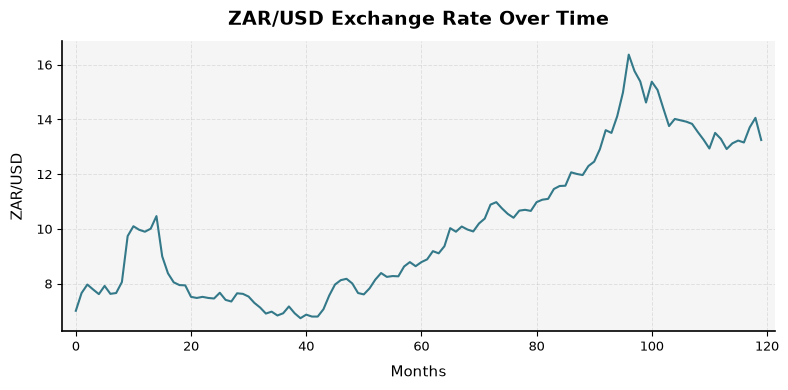

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    np.arange(len(df.Y)),
    df.Y, color = "#347989"
)

style_plot(
    ax,
    title="ZAR/USD Exchange Rate Over Time",
    xlabel="Months",
    ylabel="ZAR/USD"
)

plt.tight_layout()
plt.show()

Let's create a plot to visualise the value of exports from South Africa, measured in millions of ZAR. This helps show us any trends in export activity and economic performance over the same period

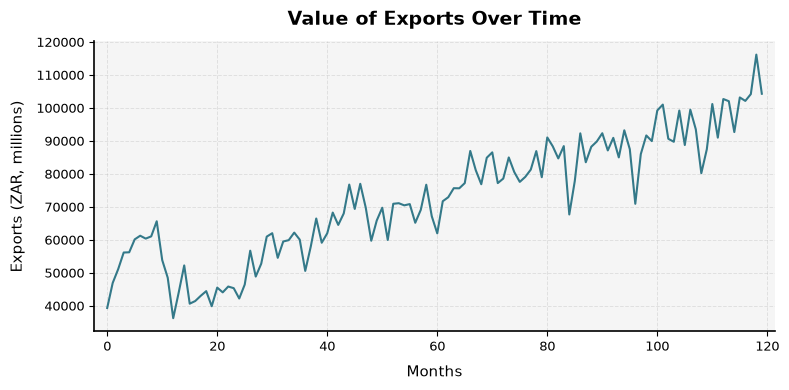

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    np.arange(len(df.X)),
    df.X, color = "#347989"
)

style_plot(
    ax,
    title="Value of Exports Over Time",
    xlabel="Months",
    ylabel="Exports (ZAR, millions)"
)

plt.tight_layout()
plt.show()

### __Example 2__
Let's try and create something a little more visually appealing than the two plots above.

- We'll plot both dependent data series on the same graph.
- We'll assign two separate y-axes: one for each series.
- We'll display a legend near the top of the plot.

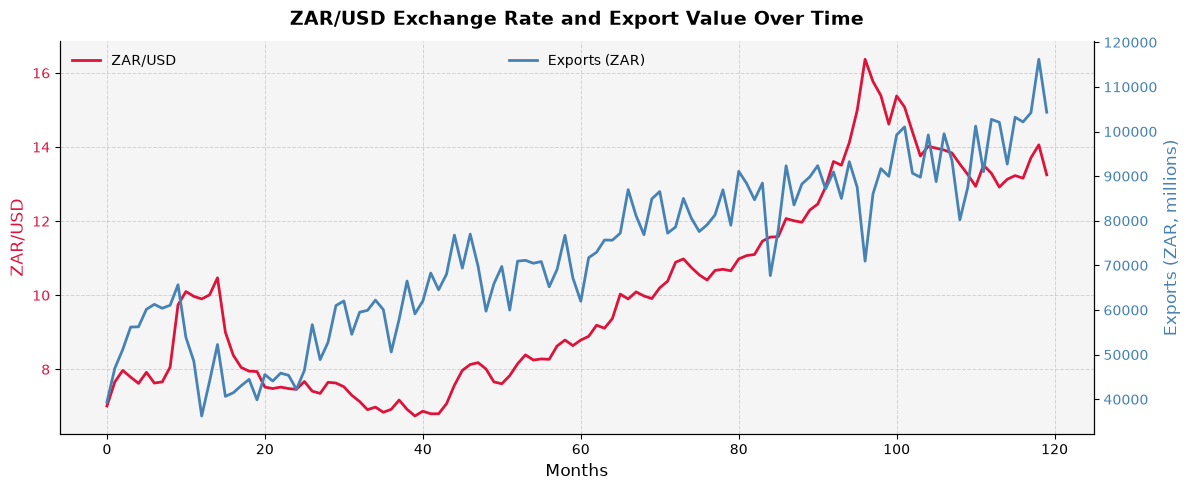

In [7]:
fig, ax, ax2 = dual_axis_plot(
    x1=np.arange(len(df.Y)),
    y1=df.Y,
    x2=np.arange(len(df.X)),
    y2=df.X,
    label1="ZAR/USD",
    label2="Exports (ZAR)",
    xlabel="Months",
    ylabel1="ZAR/USD",
    ylabel2="Exports (ZAR, millions)",
    title="ZAR/USD Exchange Rate and Export Value Over Time",
    color1="crimson",
    color2="steelblue"
)

plt.show()

---
### __Let's get started with regression__
So the plots above – although they are easy to interpret – show too many variables. We have our Y, our X, and time (months), but we're just trying to model ZAR/USD as a *function* of Exports.

**Note:** It's important to note here that we are **not** trying to model the exchange rate as a function of time.

### Example 3
Let's try and show the relationship between the two variables using a scatter plot.

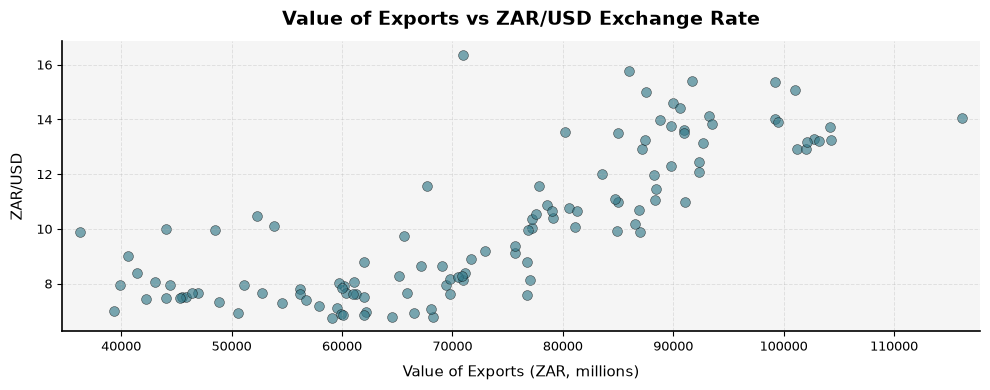

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.scatter(
    data = df,
    x = "X",
    y = "Y",
    alpha=0.65,
    color = "#347989",
    s=50,
    edgecolor="black",
    linewidth=0.4
)

style_plot(
    ax,
    title="Value of Exports vs ZAR/USD Exchange Rate",
    xlabel="Value of Exports (ZAR, millions)",
    ylabel="ZAR/USD",
    grid=True,
)

plt.tight_layout()
plt.show()

We would like to be able to fit a line to this data such that we can make predictions of Y for new values of X. We would like to calculate values for the slope, $m$, and the y-intercept, $c$, such that the line represented by $y = mx + c$ lies as close as possible to the points shown in the scatter plot above.

---
### __Finding the best fit line__
Let's say we have estimated some values for $m$ and $c$. We could plug in all of our values of X to find the corresponding values of Y. These *new* values of Y could be compared to the *actual* values of Y to assess the fit of the line. This becomes tedious as the number of data points increases.

### __Example 4__

Looking at the data, we can guess the values of the slope and intercept of the line. We'll use a rough estimate of the slope as $\frac{rise}{run} = \frac{16}{80000} = 0.0002$. For the intercept, we'll just take a guess and call it $-3$.

Let's plot a line with values of $m = 0.0002$ and $c = -3$.

First, we will need to generate some values of y using the following formula:

$$\hat{y}_i = mx_i + c$$

In [9]:
def gen_y(x_list, m, c):
    y_gen = []

    for x_i in x_list:
        y_i = m * x_i + c
        y_gen.append(y_i)

    return y_gen

In [10]:
# Sort X values
x_sorted = np.sort(df["X"])

# Generate predicted Y values using sorted X
y_sorted = gen_y(
    x_sorted,
    0.0002,
    -3
)


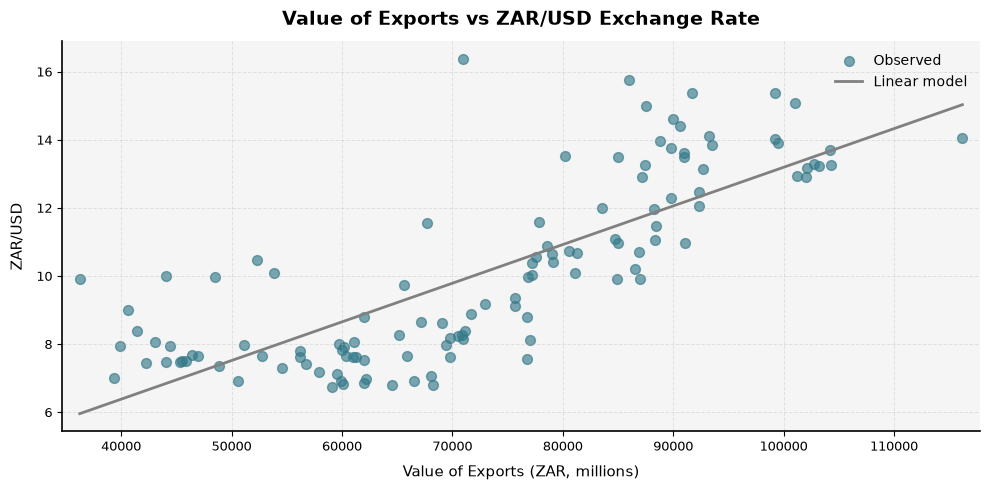

In [24]:
# Create the figure and axis
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the original observations
ax.scatter(
    data = df,
    x = "X",
    y = "Y",
    color = "#347989",
    alpha=0.65,
    s=50,
    label="Observed"
)

# Plot the linear model as a continuous line
ax.plot(
    x_sorted,
    y_sorted,
    linewidth=2,
    color="gray",
    label="Linear model"
)

# Apply consistent styling
style_plot(
    ax,
    title="Value of Exports vs ZAR/USD Exchange Rate",
    xlabel="Value of Exports (ZAR, millions)",
    ylabel="ZAR/USD",
    grid=True
)

# Add legend
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

At first glance, it looks like the fit of this line is not too bad!

### __Example 5__

**Let's check the calculated fit of the line** by measuring how far the true y-values of each point are from their corresponding y-value on the line.

We'll use the equation below to calculate the error of each generated value of y:

$$e_i = y_i - \hat{y}_i$$

In [13]:
y_gen = gen_y(
    df["X"],
    0.0002,
    -3
)


errors = np.array(df.Y - y_gen)
errors = np.round(errors, 2)

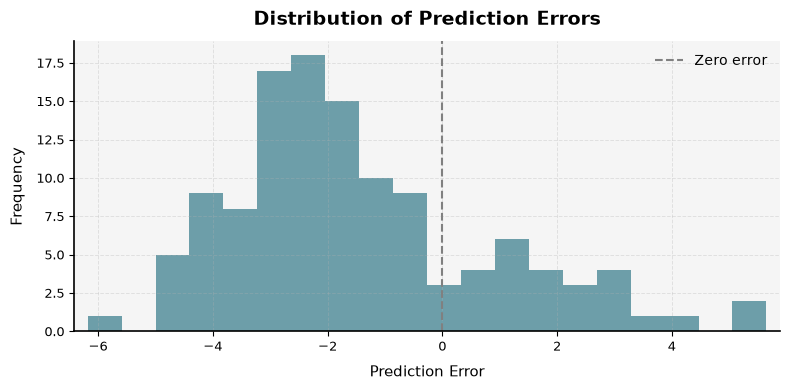

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    errors,
    bins=20,
    alpha=0.7,
    color = "#347989"
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Zero error"
)

style_plot(
    ax,
    title="Distribution of Prediction Errors",
    xlabel="Prediction Error",
    ylabel="Frequency",
    grid=True,
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In addition to having some very large errors, we can also see that most of the errors are negative numbers. Ideally, we want our errors to be evenly distributed on either side of zero – we want our line to best fit the data, i.e. no bias.

We can measure the overall error of the fit by calculating the **residual sum of squares**:

$$RSS = \sum_{i=1}^n(y_i-\hat{y}_i)^2$$

The RSS finds the difference between the y-value of each data point and our estimated line (which may be either negative or positive), squares the difference, and then adds all the differences up. In other words, it's the sum of the squares of all the errors we calculated before.

---
### __Least Squares Regression__

Imagine you have house price data: the bigger the house, the higher the price, roughly. But how do you draw one line through that scatter of points that best captures the pattern, so you can predict the price of a house you have never seen before? That is exactly what least squares regression solves. In this lesson, you will see how the method works, why it minimizes squared errors, and how to put it into practice with scikit-learn.



Least squares is a method used in regression analysis to find the best-fitting straight line through a set of data points. It does this by minimising the sum of the squares of the residuals between the observed values and those predicted by the line, i.e.:
$$Q = \sum_{i=1}^n(y_i-\hat{y}_i)^2$$

The formulae for the slope, \(m\), and the intercept, \(c\), are determined by minimising the equation for the sum of the squared prediction errors:
$$Q = \sum_{i=1}^n(y_i-(m x_i+c))^2$$

Optimal values for \(m\) and \(c\) are found by differentiating \(Q\) with respect to \(m\) and \(c\), setting both equal to 0, and then solving for \(m\) and \(c\).

The equations for \(m\) and \(c\) are:

$$m = \frac{\sum_{i=1}^n(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^n(x_i-\bar{x})^2}$$

and:

$$c = \bar{y} - m \bar{x}$$

where $\bar{y}$ and $\bar{x}$ are the mean values of \(y\) and \(x\) in our dataset, respectively.

### Example 1

Let's calculate these values in Python, where \(c\) is the intercept and \(m\) is the slope.

In [16]:
# Extract values of X and Y as numpy arrays for mathematical operations
X = df.X.values
Y = df.Y.values

# Calculate mean of X and Y
x_bar = np.mean(X)
y_bar = np.mean(Y)

# Calculate the slope (m) of the regression line using the least squares method
m = sum((X - x_bar) * (Y - y_bar)) / sum((X - x_bar) ** 2)

# Calculate the intercept (c) of the regression line
c = y_bar - m * x_bar

# Output the calculated slope and intercept
print(f"Slope = {m:.6f}")
print(f"Intercept = {c:.6f}")

Slope = 0.000114
Intercept = 1.844811


In [17]:
# Generate predicted Y-values from the linear equation
def predict_y(x_list, m, c):
    """
    Generate predicted Y-values using a linear equation.

    Parameters
    ----------
    x_list : array-like
        X-values.

    m : float
        Slope.

    c : float
        Intercept.

    Returns
    -------
    array-like
        Predicted Y-values.
    """
    return m * x_list + c


# Generate predicted Y-values
y_pred = predict_y(df["X"], m, c)

# Sort X-values for a continuous regression line
sort_idx = np.argsort(df["X"])
x_sorted = df["X"].iloc[sort_idx]
y_sorted = y_pred.iloc[sort_idx]

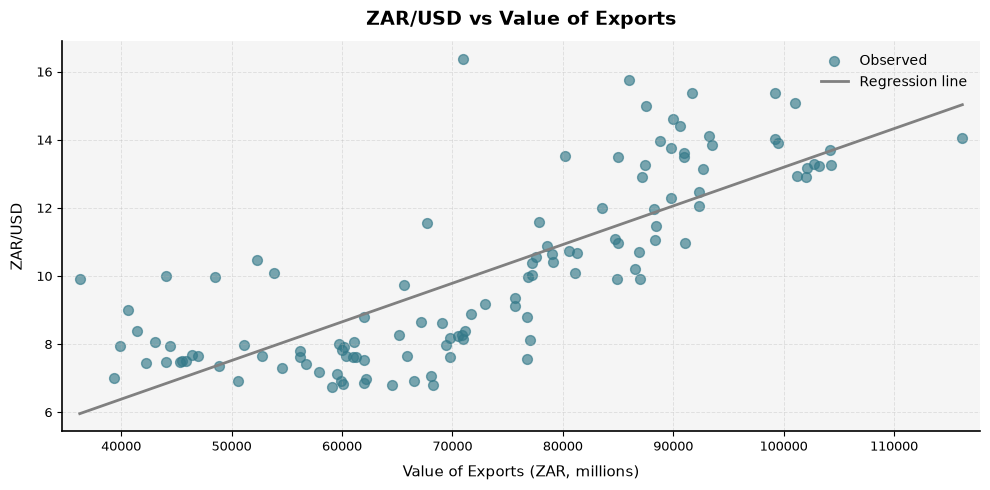

In [22]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 5))

# Plot original observations
ax.scatter(
    data = df,
    x = "X",
    y = "Y",
    alpha=0.65,
    color = "#347989",
    s=50,
    label="Observed"
)

# Plot regression line
ax.plot(
    x_sorted,
    y_sorted,
    linewidth=2,
    color="gray",
    label="Regression line"
)

# Apply consistent styling
style_plot(
    ax,
    title="ZAR/USD vs Value of Exports",
    xlabel="Value of Exports (ZAR, millions)",
    ylabel="ZAR/USD",
    grid=True,
)

# Add legend
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [20]:
residuals = np.array(y_pred - df.Y) # Calculate the residuals by subtracting the observed Y values from the generated Y values
print(np.round(residuals, 2)) # Print the residuals, rounded to 2 decimal places

[-0.7  -0.49 -0.32  0.43  0.61  0.75  1.17  1.04  0.72 -0.44 -2.14 -2.62
 -3.94 -3.16 -2.69 -2.54 -1.83 -1.32 -1.06 -1.57 -0.51 -0.63 -0.47 -0.49
 -0.82 -0.55  0.87  0.04  0.19  1.14  1.36  0.74  1.47  1.74  1.93  1.82
  0.67  1.25  2.47  1.82  2.01  2.8   2.37  2.5   2.99  1.75  2.46  1.58
  0.62  1.66  2.15  0.82  1.75  1.53  1.59  1.61  0.98  1.06  1.77  0.83
  0.09  1.1   0.93  1.32  1.06  0.58  1.82  0.96  0.59  1.57  1.47  0.23
 -0.12  0.51  0.24  0.1   0.41  0.4   1.01  0.15  1.2   0.8   0.36  0.42
 -2.04 -0.9   0.25 -0.68 -0.11 -0.26 -0.13 -1.19 -1.44 -2.02 -1.69 -3.21
 -6.47 -4.16 -3.14 -2.56 -2.27 -1.77 -2.27 -1.73 -0.91 -2.05 -0.78 -1.38
 -2.59 -1.49  0.39 -1.33  0.21  0.51 -0.76  0.33  0.28 -0.04  0.97  0.44]


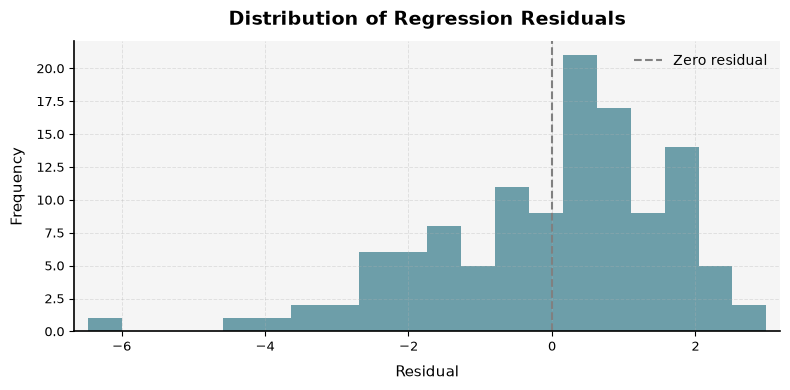

In [21]:
# Create the figure and axis
fig, ax = plt.subplots(figsize=(8, 4))

# Plot the residuals
ax.hist(
    residuals,
    bins=20,
    alpha=0.7,
    color = "#347989"
)

# Add a reference line at zero
ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    color = "gray",
    label="Zero residual"
)

# Apply consistent styling
style_plot(
    ax,
    title="Distribution of Regression Residuals",
    xlabel="Residual",
    ylabel="Frequency",
    grid=True,
)

# Add legend
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### __Linear Regression__

In [25]:
from sklearn.linear_model import LinearRegression

In [26]:
# Initialise the LinearRegression model
lm = LinearRegression()

In [27]:
# Reshape the X array to a 2D array as required by scikit-learn, converting from pandas Series to numpy array if necessary
X = df.X.values[:, np.newaxis]
y = df.Y

In [28]:
# Fit the linear model to the data
lm.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.845
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[199994.2]


In [29]:
slope = lm.coef_[0]
intercept = lm.intercept_

print(f"Slope = {slope:.4f}")
print(f"Intercept = {intercept:.4f}")

Slope = 0.0001
Intercept = 1.8448


In [30]:
y_pred = lm.predict(X)

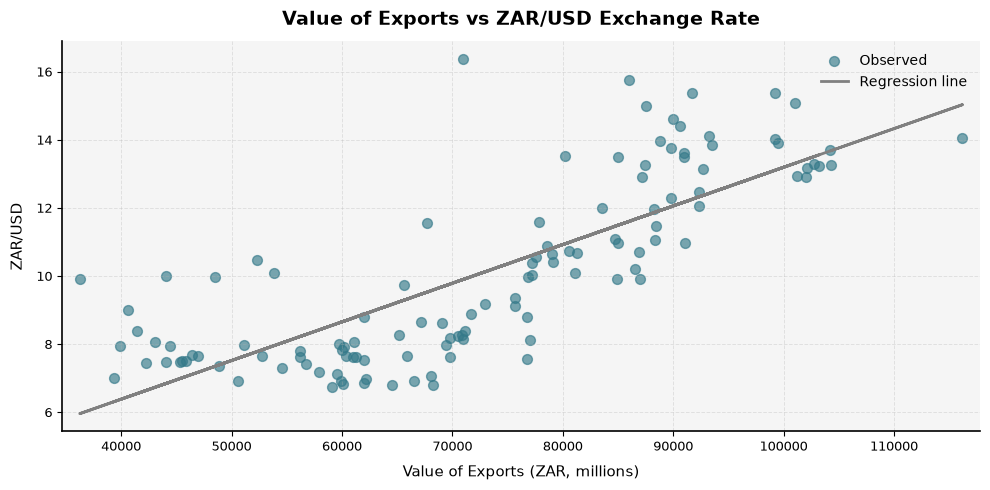

In [32]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the original data
ax.scatter(
    X,
    y,
    alpha=0.65,
    color = "#347989",
    s=50,
    label="Observed"
)

# Plot the predicted regression line
ax.plot(
    X,
    y_pred,
    linewidth=2,
    color="gray",
    label="Regression line"
)

# Apply consistent styling
style_plot(
    ax,
    title="Value of Exports vs ZAR/USD Exchange Rate",
    xlabel="Value of Exports (ZAR, millions)",
    ylabel="ZAR/USD",
    grid=True,
)

# Add legend
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### __Assessing the model accuracy__
We can measure the overall error of the fit by calculating the **residual sum of squares**:

$$RSS = \sum_{i=1}^n(y_i-\hat{y}_i)^2$$

In [33]:
print('Residual sum of squares:', ((y - y_pred) ** 2).sum())

Residual sum of squares: 321.4571665525765


---
### __Sci-kit learn error metrics__
Sci-kit learn also has implementations of common error metrics which will make things easier for us to assess the fit of our model.

In addition to RSS, there are some other metrics we can use:

**Mean squared error (MSE)** measures the average of the squares of the errors between actual and predicted values in a linear regression model. It assesses the fit of the model by quantifying the variance between predicted and observed values, with lower values indicating a better fit.
$$MSE = \frac{RSS}{n}$$
$$MSE = \frac{1}{n}\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**R squared ($R^2$)** quantifies the proportion of the variance in the dependent variable that is predictable from the independent variable(s) in a linear regression. It assesses the strength of the relationship between the model's predictions and the actual data, with values closer to 1 indicating a stronger relationship.
$$R^2 = 1 - \frac{RSS}{TSS}$$
$$R^2 = 1 - \frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2}$$

We can compute these metrics using sci-kit learn as follows:

In [34]:
from sklearn.metrics import mean_squared_error, r2_score

In [35]:
# Calculate and print the mean squared error (MSE) between the observed and predicted Y values
print('MSE:', mean_squared_error(y, y_pred))

MSE: 2.6788097212714708


In [36]:
# Calculate and print the RSS by multiplying the MSE by the number of observations
print('Residual sum of squares:', mean_squared_error(y, y_pred) * len(X))

Residual sum of squares: 321.4571665525765


In [37]:
# Calculate and print the R-squared value, a measure of how well the observed values are replicated by the model
print('R_squared:', r2_score(y, y_pred))

R_squared: 0.6158417476896207


---
### __Quiz__


__Question 1:__

While a linear regression model's line of best fit is excellent for making predictions, developers must understand its real-world limits. What is a primary pitfall or limitation when using a fitted equation to make decisions?

__Answer:__

Extrapolation-attempting to predict values far outside the range of the original input data used to train the model, where the linear relationship may no longer hold true.

__Question 2:__

A statistician calculates a correlation coefficient (r) of -0.85 between a city's reliance on public transit and its per-capita carbon emissions. What does this specific metric tell us about the relationship between these two variables?

__Answer:__

There is a strong, negative linear relationship, meaning higher public transit reliance is strongly associated with lower carbon emissions.

__Question 3:__

The standard method for determining the line of best fit in a simple linear regression model is Ordinary Least Squares (OLS). How does this method mathematically calculate the optimal line?

__Answer:__

It minimizes the sum of the squared residuals, where a residual is the vertical distance between an observed data point and the predicted line

__Question 4:__

A developer is using Python's scikit-learn library to train a linear regression model on a dataset tracking advertising spend (X) and company revenue (y). Assume X has been properly reshaped. Which code snippet correctly fits the model and extracts the calculated slope?

__Answer:__

```Python
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)
slope = model.coef_[0]

```

__Question 5:__

A data analyst fits a simple linear regression model to predict ice cream sales based on daily temperature. The resulting equation for the line of best fit is:
$$Sales = 50 + 12 \times \space Temperature$$
How should the slope and the intercept of this model be interpreted?

__Answer:__

The intercept means that if the temperature is 0 degrees, predicted sales are 50 units; the slope means each 1-degree increase in temperature increases predicted sales by 12 units.